# sigker-nspdes: 1D stochastic Ginzburg–Landau

See `README.md` for method, choices and results.

In [1]:
import numpy as np
import torch
import wandb
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from sigker_nspdes import (
    GinzburgLandauDataset, SigKernel, signature_kernel_score, conditional_kernel_score, energy_score,
    score_transform, resolve_sigma,
    build_generator, build_kernel, score_loss, train, load_checkpoint, generate, ks_marginals,
)

REAL_C, GEN_C = "#2a78d6", "#eb6834"   # real = blue, generated = orange throughout
FIELD_CMAP    = "RdBu_r"               # diverging around u = 0

In [2]:
CFG = dict(
    # --- data: stochastic Ginzburg-Landau (Phi^4_1) ---
    n_train  = 40960,
    n_test   = 1024,
    n_per_ic = 1,           # noise realisations per u0 (n_train // n_per_ic distinct u0s)
    dim_x    = 64,          # interior grid points of [0, 1]
    dim_t    = 32,          # time points on [0, T]
    T        = 0.2,
    sigma_gl = 1.0,         # noise amplitude of the data SPDE
    kappa    = 0.5,         # amplitude of the random part of u0
    substeps = 20,          # fine solver steps per recorded time step

    # --- generator (Neural SPDE, fixed-point solver) ---
    noise_size   = 2,
    hidden_size  = 16,
    num_layers   = 1,
    modes_x      = 32,
    modes_t      = 16,
    n_iter       = 4,       # Picard iterations
    noise_type   = "white", # "white" or "colored"
    readout_size = 128,
    norm         = "none",  # "batch" (reference BatchNorm, always batch stats) or "none";
                            # "none" with m_per_u0, else BN couples the M copies of a u0

    # --- loss ---
    score        = "energy", # "sigkernel" or "energy" (calorimeter notes eq. 63, raw fields;
                                 # needs m_per_u0 >= 2)
    beta         = 1.0,     # energy-score exponent in (0, 2); energy only

    # --- signature kernel score ---
    kernel_type  = "rbf",   # RBF on spatial slices (reference "rbf_id")
    sigma        = "multiscale", # float, list, "median", or "multiscale" = median x (1/64, 1/8, 1):
                                 # average of signature kernels at 3 bandwidths (reference SummedKernel)
    dyadic_order = 1,
    max_batch    = 128,
    alpha        = 0.1,     # score is computed on alpha * cumsum_t(u), as the reference
    m_per_u0     = 2,    # M fields per u0, each group scored against its own real field
                            # (conditional score); None = reference pooled score

    # --- training ---
    batch_size     = 128,   # u0s per step; the generator runs on batch_size * m_per_u0 fields
                            # (pooled score at 128: ~7 GB peak, ~0.4 s/step on an RTX 4090)
    steps          = 3000,
    optimizer      = "Adam",
    lr             = 1e-3,
    weight_decay   = 0.0,
    grad_clip      = 10.0,
    swa_step_start = 1500,
    log_every      = 250,
    save_every     = 1000,
    seed           = 0,

    # --- run ---
    mode          = "train",  # "train" | "resume" | "eval"
    device        = "cuda" if torch.cuda.is_available() else "cpu",
    ckpt_dir      = None,     # None = derived from the loss below
    wandb_log     = False,
    wandb_project = "sigker-nspde",
    wandb_entity  = None,
)

# One checkpoint directory per loss, so runs with different losses never resume each other
if CFG["ckpt_dir"] is None:
    if CFG["score"] == "energy":
        tag = f"energy_beta{CFG['beta']:g}_M{CFG['m_per_u0']}"
    else:
        tag = f"cond_M{CFG['m_per_u0']}" if CFG["m_per_u0"] else "pooled"
    CFG["ckpt_dir"] = f"checkpoints/ginzburg_landau_1d_{tag}"
print(f"loss: {CFG['score']}   ckpt_dir: {CFG['ckpt_dir']}")

loss: energy   ckpt_dir: checkpoints/ginzburg_landau_1d_energy_beta1_M2


## Dataset

In [3]:
torch.manual_seed(CFG["seed"]); np.random.seed(CFG["seed"])

data_kw = dict(dim_x=CFG["dim_x"], dim_t=CFG["dim_t"], T=CFG["T"], sigma=CFG["sigma_gl"],
               kappa=CFG["kappa"], substeps=CFG["substeps"], device=CFG["device"])
train_ds = GinzburgLandauDataset(CFG["n_train"], n_per_ic=CFG["n_per_ic"], **data_kw)
test_ds  = GinzburgLandauDataset(CFG["n_test"],  **data_kw)

train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True, drop_last=True)
test_loader  = DataLoader(test_ds,  batch_size=CFG["batch_size"], shuffle=True, drop_last=True)
ts = train_ds.ts.to(CFG["device"])
x  = train_ds.x.numpy()

CFG["sigma"] = resolve_sigma(CFG["sigma"], train_ds.fields, CFG["alpha"])
print(f"train {tuple(train_ds.fields.shape)}  test {tuple(test_ds.fields.shape)}  RBF sigma = {np.round(CFG['sigma'], 3)}")

train (40960, 32, 64)  test (1024, 32, 64)  RBF sigma = [ 0.266  2.131 17.048]


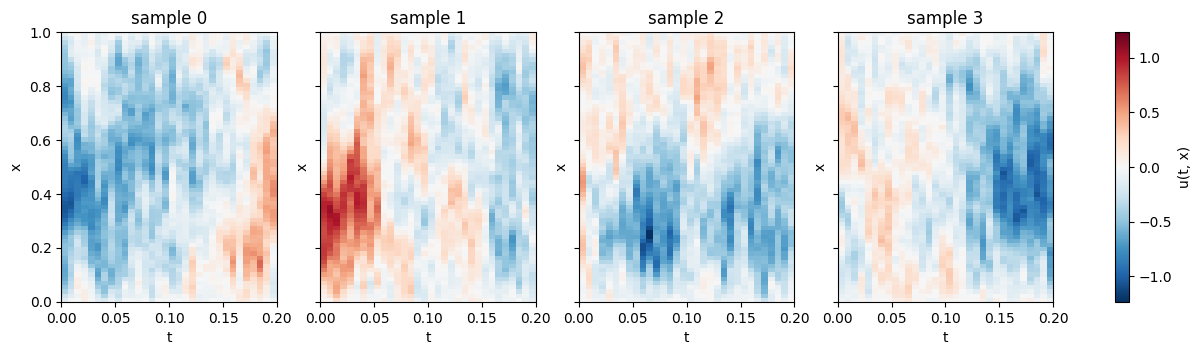

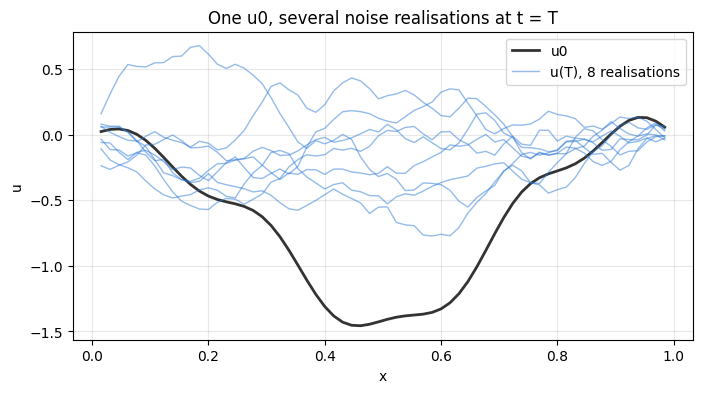

In [4]:
def show_field(ax, field, title, vmax):
    im = ax.imshow(field.T, origin="lower", aspect="auto", cmap=FIELD_CMAP, vmin=-vmax, vmax=vmax,
                   extent=[0, CFG["T"], 0, 1])
    ax.set(title=title, xlabel="t", ylabel="x")
    return im

vmax = train_ds.fields[:4].abs().max().item()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for i, ax in enumerate(axes):
    im = show_field(ax, train_ds.fields[i].numpy(), f"sample {i}", vmax)
fig.colorbar(im, ax=axes, label="u(t, x)")
plt.show()

# Same u0, several noise realisations: the stochasticity the generator must reproduce
u0 = test_ds.fields[0, 0]
same_u0 = test_ds.resimulate(u0, 8, CFG["device"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, u0, color="0.2", lw=2, label="u0")
for k, f in enumerate(same_u0):
    ax.plot(x, f[-1], color=REAL_C, alpha=0.5, lw=1, label="u(T), 8 realisations" if k == 0 else None)
ax.set(xlabel="x", ylabel="u", title="One u0, several noise realisations at t = T")
ax.legend(); ax.grid(alpha=0.3); plt.show()

## Signature kernel sanity check

Should converge to `I_0(2 sqrt(ab))` as `dyadic_order` grows.

In [5]:
from scipy.special import i0
a, b = 0.7, 1.3
X = torch.linspace(0, a, 5, dtype=torch.float64)[None, :, None]
Y = torch.linspace(0, b, 7, dtype=torch.float64)[None, :, None]
for o in range(5):
    k = SigKernel("linear", dyadic_order=o)(X, Y).item()
    print(f"dyadic_order={o}:  k_sig={k:.8f}   exact={i0(2*np.sqrt(a*b)):.8f}   err={abs(k - i0(2*np.sqrt(a*b))):.2e}")

dyadic_order=0:  k_sig=2.13998678   exact=2.13919252   err=7.94e-04
dyadic_order=1:  k_sig=2.13944062   exact=2.13919252   err=2.48e-04
dyadic_order=2:  k_sig=2.13926050   exact=2.13919252   err=6.80e-05
dyadic_order=3:  k_sig=2.13921024   exact=2.13919252   err=1.77e-05
dyadic_order=4:  k_sig=2.13919704   exact=2.13919252   err=4.52e-06


## Model

NeuralSPDEGenerator(
  (noise): QWienerNoise()
  (lift): Linear(in_features=1, out_features=16, bias=True)
  (func): LocalOperators(
    (F): Sequential(
      (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1))
      (1): Tanh()
    )
    (G): Sequential(
      (0): Conv2d(16, 32, kernel_size=(1, 1), stride=(1, 1))
      (1): Tanh()
    )
  )
  (conv): KernelConvolution()
  (readout): Sequential(
    (0): Linear(in_features=16, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
)
Parameters: 134.2 K


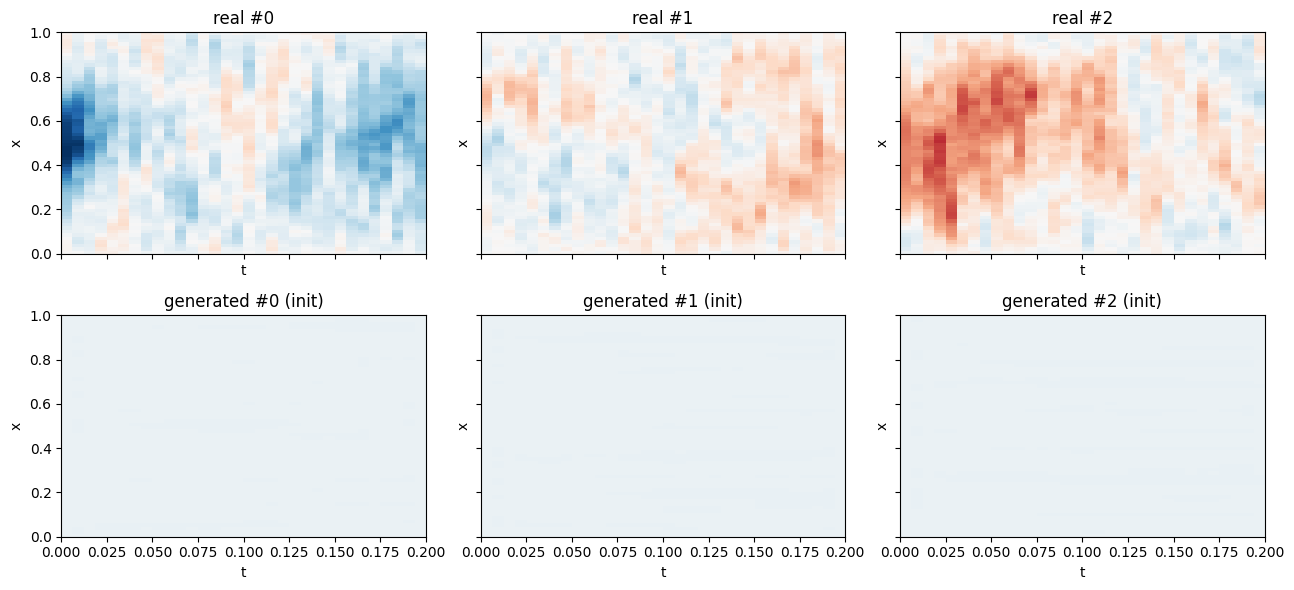

In [6]:
generator = build_generator(CFG).to(CFG["device"])
print(generator)
print(f"Parameters: {sum(p.numel() for p in generator.parameters()) / 1e3:.1f} K")

# Generator at initialisation, from the same u0s as real samples
real = test_ds.fields[:CFG["batch_size"]]
fake = generate(generator, real[:, 0], ts)
vmax = real[:3].abs().max().item()
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for i in range(3):
    show_field(axes[0, i], real[i].numpy(), f"real #{i}", vmax)
    show_field(axes[1, i], fake[i].numpy(), f"generated #{i} (init)", vmax)
plt.tight_layout(); plt.show()

## Train

Real-vs-real level below is the target loss.

In [7]:
if CFG["wandb_log"]:
    wandb.init(project=CFG["wandb_project"], entity=CFG["wandb_entity"], config=CFG)

with torch.no_grad():
    kernel = build_kernel(CFG)
    r1, r2 = (score_transform(test_ds.fields[i*128:(i+1)*128].to(CFG["device"]), CFG["alpha"]) for i in (0, 1))
    pooled_floor = signature_kernel_score(kernel, r1, r2).item()   # pooled sigkernel level, for the final metric
    real_floor   = pooled_floor
    if CFG["score"] == "energy" or CFG["m_per_u0"]:
        # Conditional level: M + 1 true fields per u0, M scored against the last one
        M   = CFG["m_per_u0"]
        grp = torch.stack([test_ds.resimulate(u0, M + 1, CFG["device"]) for u0 in test_ds.fields[:64, 0]])
        grp = grp.to(CFG["device"])
        if CFG["score"] == "energy":
            real_floor = energy_score(grp[:, :M], grp[:, M], CFG["beta"]).item()
        else:
            grp = score_transform(grp, CFG["alpha"])
            real_floor = conditional_kernel_score(kernel, grp[:, :M], grp[:, M]).item()
print(f"real-vs-real score, pooled sigkernel: {pooled_floor:.4f}   training loss ({CFG['score']}) target: {real_floor:.4f}")

real-vs-real score, pooled sigkernel: -2.7312   training loss (energy) target: 8.5714


In [8]:
if CFG["mode"] in ("train", "resume"):
    generator, avg_generator, loss_history, test_loss_history = train(CFG, train_loader, test_loader)

  Parameters : 134.2 K


Step   250/3000  |  loss=9.94107  grad_norm=5.864  test_loss=8.82065


Step   500/3000  |  loss=8.82927  grad_norm=2.628  test_loss=8.78182


Step   750/3000  |  loss=8.80063  grad_norm=13.374  test_loss=8.97568


Step  1000/3000  |  loss=8.80496  grad_norm=7.001  test_loss=8.76542
  -> saved checkpoints/ginzburg_landau_1d_energy_beta1_M2/ckpt2026-10-23_12-08_step001000.pt


...

Step  2000/3000  |  loss=8.75335  grad_norm=3.382  test_loss=8.87697
  -> saved checkpoints/ginzburg_landau_1d_energy_beta1_M2/ckpt2026-10-23_12-09_step002000.pt


Step  2250/3000  |  loss=8.75499  grad_norm=4.267  test_loss=8.71542


Step  2500/3000  |  loss=8.75414  grad_norm=4.372  test_loss=8.67523


Step  2750/3000  |  loss=8.75920  grad_norm=9.843  test_loss=8.61750


Step  3000/3000  |  loss=8.74183  grad_norm=3.121  test_loss=8.91811
  -> saved checkpoints/ginzburg_landau_1d_energy_beta1_M2/ckpt2026-10-23_12-09_step003000.pt


## Load pretrained model

In [9]:
# Latest checkpoint in CFG["ckpt_dir"], with SWA-averaged weights and loss histories
generator, loaded_cfg, loss_history, test_loss_history = load_checkpoint(CFG, averaged=True)

Loading checkpoints/ginzburg_landau_1d_energy_beta1_M2/ckpt2026-10-23_12-09_step003000.pt  (step 3000)


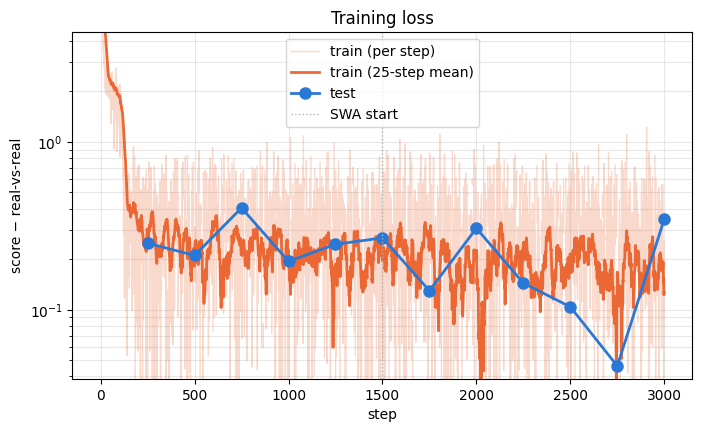

In [10]:
# Excess score over the real-vs-real level (~ MMD^2), on a log scale; per-step values
# below the floor cannot be shown and are masked
fig, ax = plt.subplots(figsize=(8, 4.5))
w = 25
pos    = lambda a: np.where(a > 0, a, np.nan)
excess = np.asarray(loss_history) - real_floor
smooth = np.convolve(excess, np.ones(w) / w, mode="valid")
ax.plot(pos(excess), color=GEN_C, alpha=0.25, lw=1, label="train (per step)")
ax.plot(np.arange(w - 1, len(excess)), pos(smooth), color=GEN_C, lw=2, label=f"train ({w}-step mean)")
shown = [smooth]
if test_loss_history:
    s, l = zip(*test_loss_history)
    l = np.asarray(l) - real_floor
    ax.plot(s, pos(l), "o-", color=REAL_C, ms=8, lw=2, label="test")
    shown.append(l)
ax.axvline(loaded_cfg["swa_step_start"], color="0.7", ls=":", lw=1, label="SWA start")
# y-range: 1st-99th percentile of the smoothed and test curves, ignoring early spikes
v = np.concatenate(shown); v = v[v > 0]
lo, hi = np.percentile(v, [1, 99])
ax.set_yscale("log"); ax.set_ylim(lo / 2, hi * 2)
ax.set(xlabel="step", ylabel="score − real-vs-real", title="Training loss")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()

## Evaluation

1. Population: generated vs test fields.
2. Given one u0: 1000 generated vs 1000 resimulated fields.

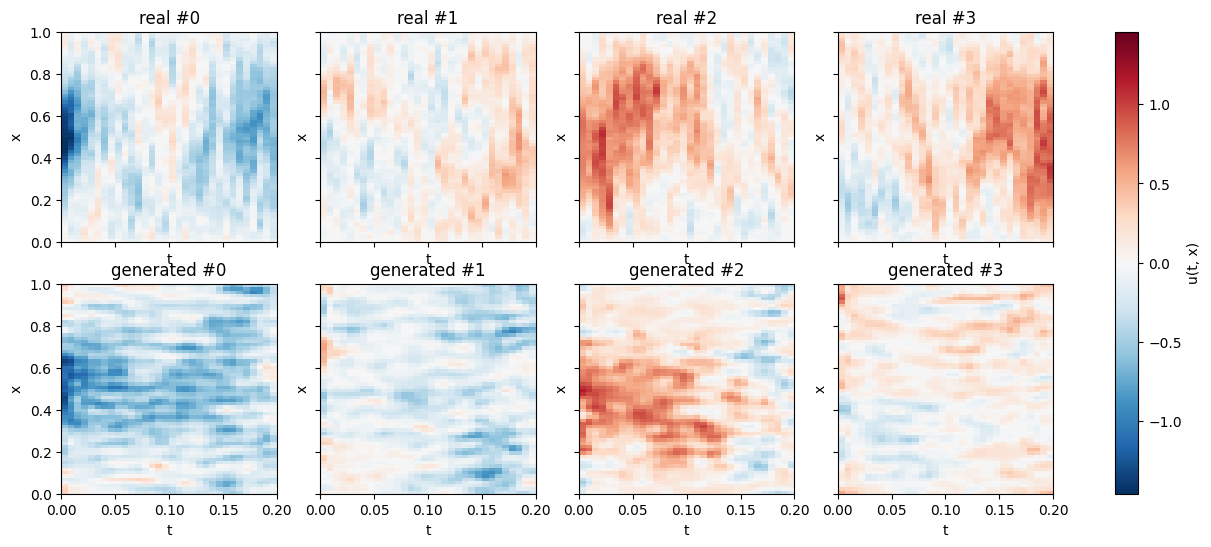

pooled sigkernel score generated vs test: -2.1699 ± 0.0344   (real-vs-real: -2.7312)
training loss (energy) on test: 8.7820 ± 0.1788   (real-vs-real: 8.5714)


In [11]:
real_pop = test_ds.fields
fake_pop = generate(generator, real_pop[:, 0], ts)

# Side by side: real vs generated from the same u0
vmax = real_pop[:4].abs().max().item()
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True, sharey=True)
for i in range(4):
    show_field(axes[0, i], real_pop[i].numpy(), f"real #{i}", vmax)
    im = show_field(axes[1, i], fake_pop[i].numpy(), f"generated #{i}", vmax)
fig.colorbar(im, ax=axes, label="u(t, x)")
plt.show()

# Final pooled score on held-out data vs the pooled real-vs-real level
with torch.no_grad():
    kernel = build_kernel(loaded_cfg)
    gen_scores = []
    for i in range(4):
        y = real_pop[i*128:(i+1)*128].to(CFG["device"])
        gen_scores.append(signature_kernel_score(kernel, score_transform(fake_pop[i*128:(i+1)*128].to(CFG["device"]), CFG["alpha"]),
                                                 score_transform(y, CFG["alpha"])).item())
    # Training loss (whichever score was used) on test batches vs its own real-vs-real level
    test_scores = [score_loss(generator, kernel, ts, test_ds.fields[i*128:(i+1)*128].to(CFG["device"]), loaded_cfg).item()
                   for i in range(4)]
print(f"pooled sigkernel score generated vs test: {np.mean(gen_scores):.4f} ± {np.std(gen_scores):.4f}   (real-vs-real: {pooled_floor:.4f})")
print(f"training loss ({loaded_cfg.get('score', 'sigkernel')}) on test: {np.mean(test_scores):.4f} ± {np.std(test_scores):.4f}   (real-vs-real: {real_floor:.4f})")

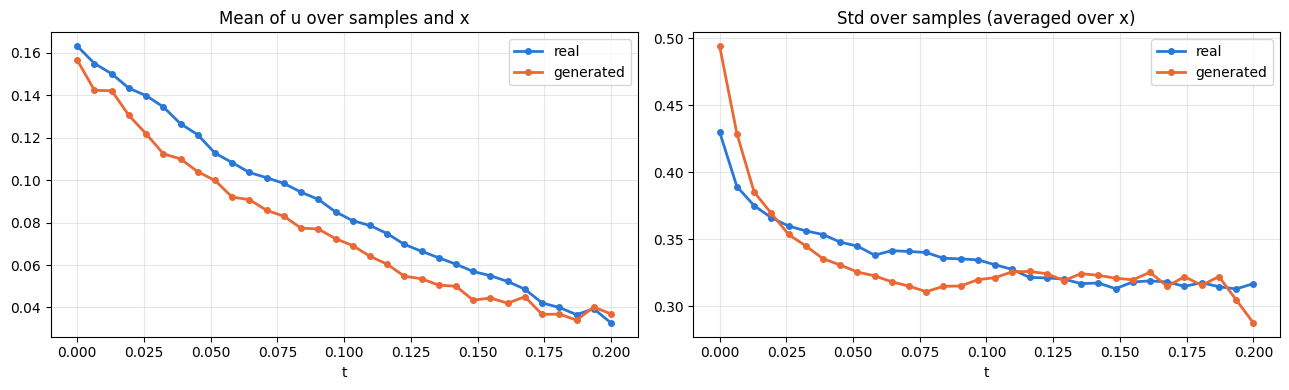

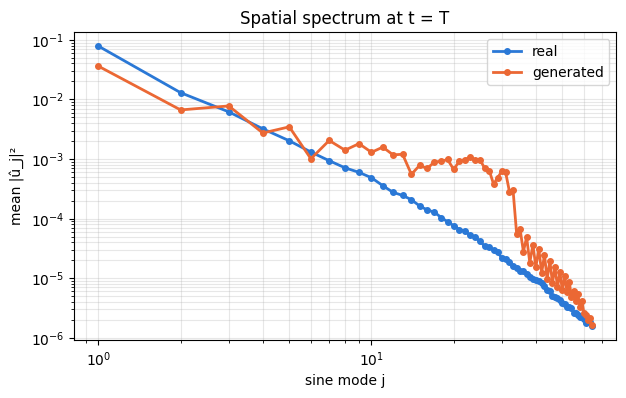

In [12]:
# Population statistics over time: mean and std of u(t, .) averaged over x
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
t_np = train_ds.ts.numpy()
for arr, c, lab in [(real_pop, REAL_C, "real"), (fake_pop, GEN_C, "generated")]:
    axes[0].plot(t_np, arr.mean(dim=(0, 2)), "o-", color=c, ms=4, lw=2, label=lab)
    axes[1].plot(t_np, arr.std(dim=0).mean(dim=1), "o-", color=c, ms=4, lw=2, label=lab)
axes[0].set(title="Mean of u over samples and x", xlabel="t")
axes[1].set(title="Std over samples (averaged over x)", xlabel="t")
for ax in axes: ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Spatial power spectrum at t = T (sine-mode energy), averaged over samples
def sine_spectrum(fields):
    from sigker_nspdes import sine_basis
    E = sine_basis(fields.shape[-1]).float()
    return ((fields @ E / (fields.shape[-1] + 1)) ** 2).mean(0)

modes = np.arange(1, CFG["dim_x"] + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(modes, sine_spectrum(real_pop[:, -1]), "o-", color=REAL_C, ms=4, lw=2, label="real")
ax.loglog(modes, sine_spectrum(fake_pop[:, -1]), "o-", color=GEN_C, ms=4, lw=2, label="generated")
ax.set(xlabel="sine mode j", ylabel="mean |û_j|²", title="Spatial spectrum at t = T")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()

u0 #0: KS accepted on 3% of (t, x) marginals | std at T gen/real 0.315/0.297 | |u(0) - u0| 0.046


u0 #1: KS accepted on 12% of (t, x) marginals | std at T gen/real 0.267/0.296 | |u(0) - u0| 0.010


u0 #2: KS accepted on 8% of (t, x) marginals | std at T gen/real 0.268/0.300 | |u(0) - u0| 0.014


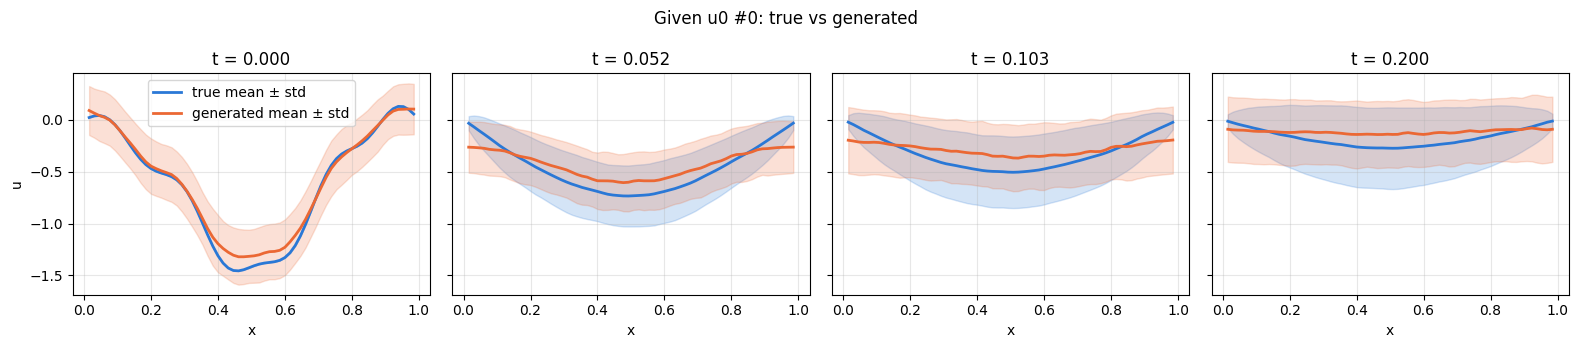

In [13]:
# Given one u0: generated vs true distribution
n_cond = 1000
cond_results = []
for idx in range(3):
    u0       = test_ds.fields[idx, 0]
    real_c   = test_ds.resimulate(u0, n_cond, CFG["device"])
    fake_c   = generate(generator, u0[None].expand(n_cond, -1), ts)
    pvals, frac = ks_marginals(fake_c, real_c)
    cond_results.append((u0, real_c, fake_c, pvals))
    print(f"u0 #{idx}: KS accepted on {frac:.0%} of (t, x) marginals | "
          f"std at T gen/real {fake_c[:, -1].std(0).mean():.3f}/{real_c[:, -1].std(0).mean():.3f} | "
          f"|u(0) - u0| {(fake_c[:, 0].mean(0) - u0).abs().mean():.3f}")

# Mean ± std profiles in x at a few times, for the first u0
u0, real_c, fake_c, pvals = cond_results[0]
t_idx = [0, CFG["dim_t"] // 4, CFG["dim_t"] // 2, CFG["dim_t"] - 1]
fig, axes = plt.subplots(1, len(t_idx), figsize=(4 * len(t_idx), 3.5), sharey=True)
for ax, ti in zip(axes, t_idx):
    for arr, c, lab in [(real_c, REAL_C, "true"), (fake_c, GEN_C, "generated")]:
        m, s = arr[:, ti].mean(0), arr[:, ti].std(0)
        ax.fill_between(x, m - s, m + s, color=c, alpha=0.2)
        ax.plot(x, m, color=c, lw=2, label=f"{lab} mean ± std")
    ax.set(title=f"t = {t_np[ti]:.3f}", xlabel="x"); ax.grid(alpha=0.3)
axes[0].set_ylabel("u"); axes[0].legend()
fig.suptitle("Given u0 #0: true vs generated"); plt.tight_layout(); plt.show()

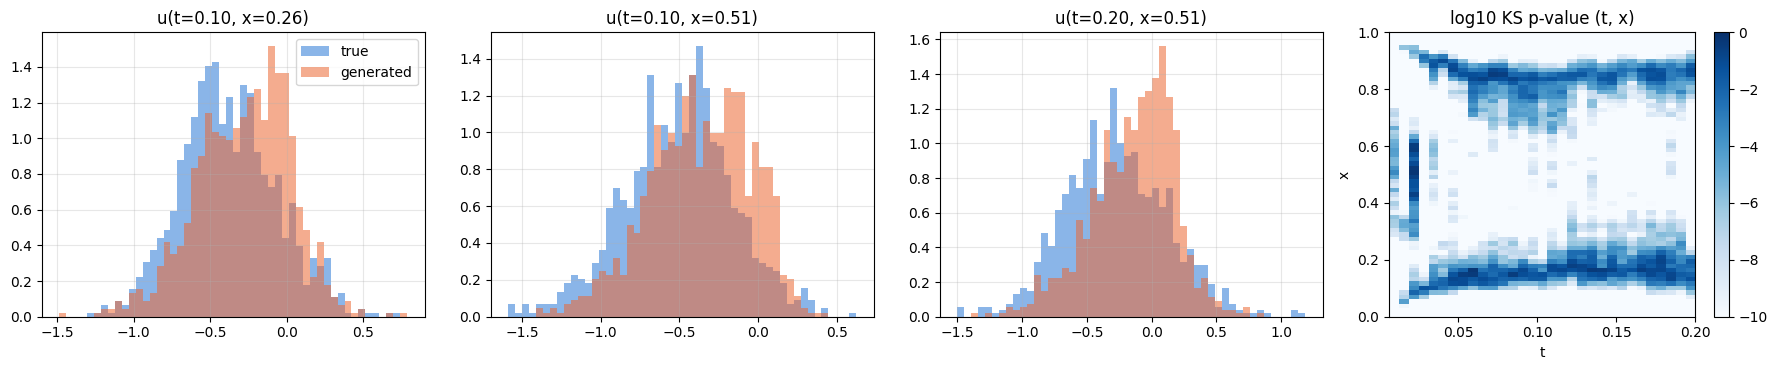

In [14]:
# Marginals given u0 #0 at a few (t, x) points, and KS p-values over the (t, x) grid
pts = [(CFG["dim_t"] // 2, CFG["dim_x"] // 4), (CFG["dim_t"] // 2, CFG["dim_x"] // 2), (CFG["dim_t"] - 1, CFG["dim_x"] // 2)]
fig, axes = plt.subplots(1, len(pts) + 1, figsize=(4.5 * (len(pts) + 1), 3.8))
for ax, (ti, xi) in zip(axes, pts):
    bins = np.histogram_bin_edges(np.concatenate([real_c[:, ti, xi], fake_c[:, ti, xi]]), bins=50)
    ax.hist(real_c[:, ti, xi].numpy(), bins=bins, density=True, color=REAL_C, alpha=0.55, label="true")
    ax.hist(fake_c[:, ti, xi].numpy(), bins=bins, density=True, color=GEN_C, alpha=0.55, label="generated")
    ax.set(title=f"u(t={t_np[ti]:.2f}, x={x[xi]:.2f})"); ax.grid(alpha=0.3)
axes[0].legend()

im = axes[-1].imshow(np.log10(np.clip(pvals.T, 1e-10, 1)), origin="lower", aspect="auto", cmap="Blues",
                     vmin=-10, vmax=0, extent=[t_np[1], CFG["T"], 0, 1])
axes[-1].set(title="log10 KS p-value (t, x)", xlabel="t", ylabel="x")
fig.colorbar(im, ax=axes[-1])
plt.tight_layout(); plt.show()

In [15]:
if wandb.run is not None:
    wandb.finish()